## 1. Import libraries and load the dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
df = pd.read_csv('ETTh1.csv')

df.head(10)

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000
5,2016-07-01 05:00:00,5.626,2.143,1.528,0.533,4.051,1.371,21.174000
6,2016-07-01 06:00:00,7.167,2.947,2.132,0.782,5.026,1.858,22.792000
7,2016-07-01 07:00:00,7.435,3.282,2.310,1.031,5.087,2.224,23.143999
8,2016-07-01 08:00:00,5.559,3.014,2.452,1.173,2.955,1.432,21.667000
9,2016-07-01 09:00:00,4.555,2.545,1.919,0.817,2.680,1.371,17.445999


In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

df.describe().transpose()

Dataset shape: (17420, 8)

Missing values:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
HUFL,17420.0,7.375141,7.067744,-22.705999,5.827,8.774,11.788,23.643999
HULL,17420.0,2.242242,2.042342,-4.756000,0.737,2.210,3.684,10.114000
MUFL,17420.0,4.300239,6.826978,-25.087999,3.296,5.970,8.635,17.341000
MULL,17420.0,0.881568,1.809293,-5.934000,-0.284,0.959,2.203,7.747000
LUFL,17420.0,3.066062,1.164506,-1.188000,2.315,2.833,3.625,8.498000
LULL,17420.0,0.856932,0.599552,-1.371000,0.670,0.975,1.218,3.046000
OT,17420.0,13.324672,8.566946,-4.080000,6.964,11.396,18.079,46.007000


In [ ]:
df['date'] = pd.to_datetime(df['date'])

df = df.sort_values('date').reset_index(drop=True)

print("Start date:", df['date'].min())
print("End date:", df['date'].max())

print("\nTime intervals:")
print(df['date'].diff().value_counts())

Start date: 2016-07-01 00:00:00
End date: 2018-06-26 19:00:00

Time intervals:
date
0 days 01:00:00    17419
Name: count, dtype: int64


* The dataset contains 17,420 observations and eight columns,
including six electrical load variables, a date column and
the target variable OT. There are no missing values.

* Unlike the weather dataset used in the lab, the ETTh1 dataset
is already sampled at hourly intervals. Therefore, no
subsampling is required. I converted the date column to
datetime format and sorted the observations chronologically.

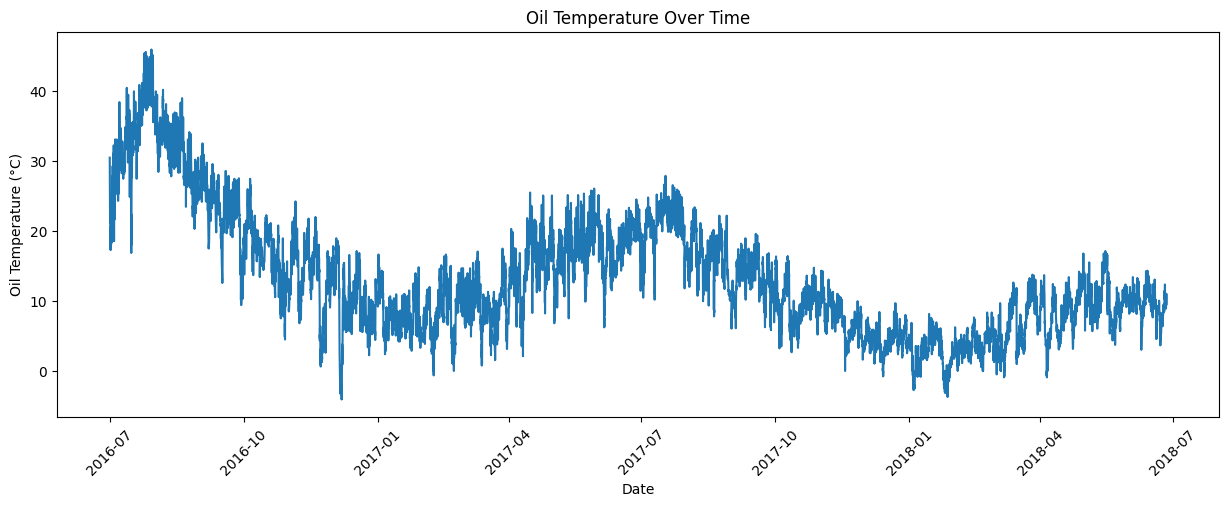

In [ ]:
temperature = df['OT']

plt.figure(figsize=(15, 5))

plt.plot(df['date'], temperature)

plt.title('Oil Temperature Over Time')
plt.xlabel('Date')
plt.ylabel('Oil Temperature (°C)')
plt.xticks(rotation=45)

plt.show()

* The oil temperature is generally higher during summer.



* The oil temperature decreases during winter.



* The pattern appears to repeat annually.



* Temperatures in the second year are generally lower than those in the first year.

# 1.2 Plot the first 20 days

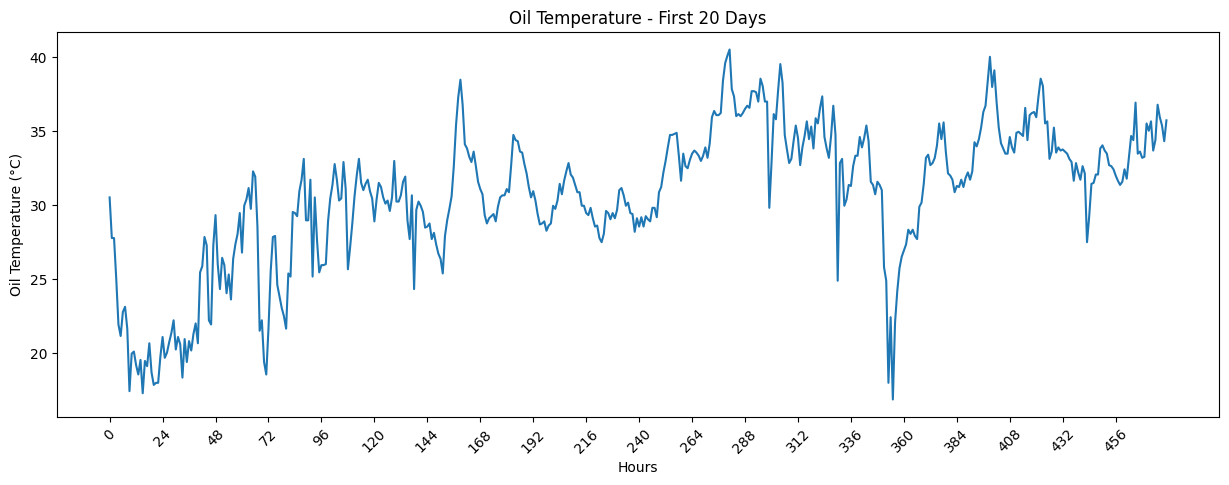

In [ ]:
plt.figure(figsize=(15, 5))

plt.xticks(np.arange(0, 20 * 24, 24), rotation=45)

plt.plot(range(20 * 24), temperature.iloc[:20 * 24])

plt.title('Oil Temperature - First 20 Days')
plt.xlabel('Hours')
plt.ylabel('Oil Temperature (°C)')

plt.show()

# 1.3 Decompose the oil temperature

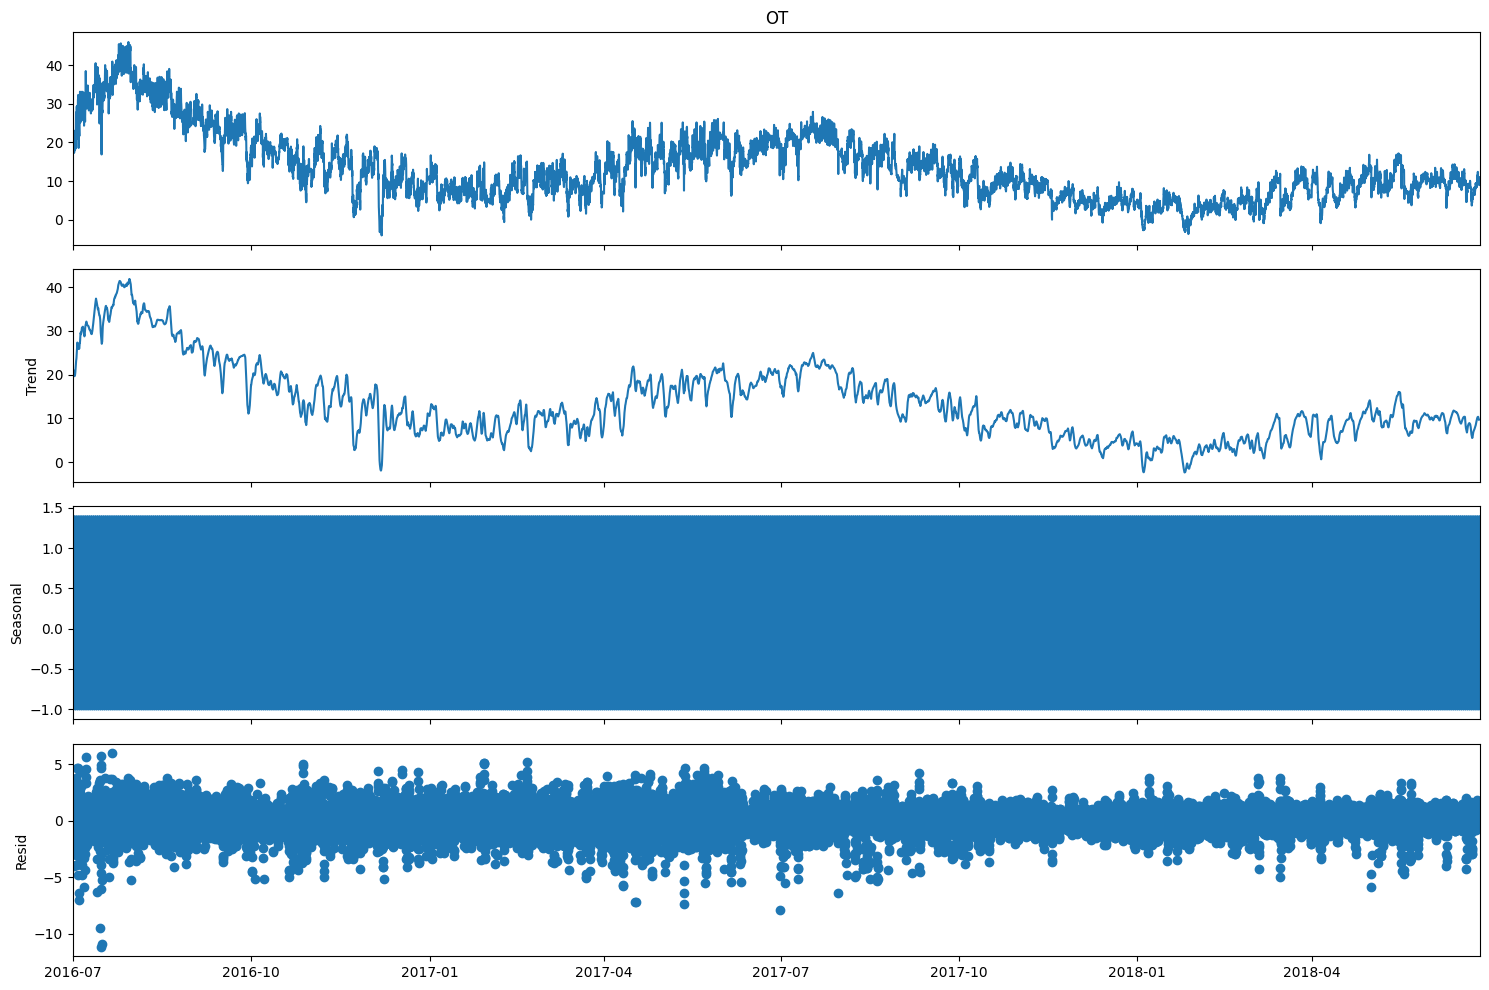

In [ ]:
ot_series = df.set_index('date')['OT']

decomposition = seasonal_decompose(
    ot_series,
    model='additive',
    period=24
)

fig = decomposition.plot()
fig.set_size_inches(15, 10)

plt.tight_layout()
plt.show()

## 1.4 Examine the seasonal component

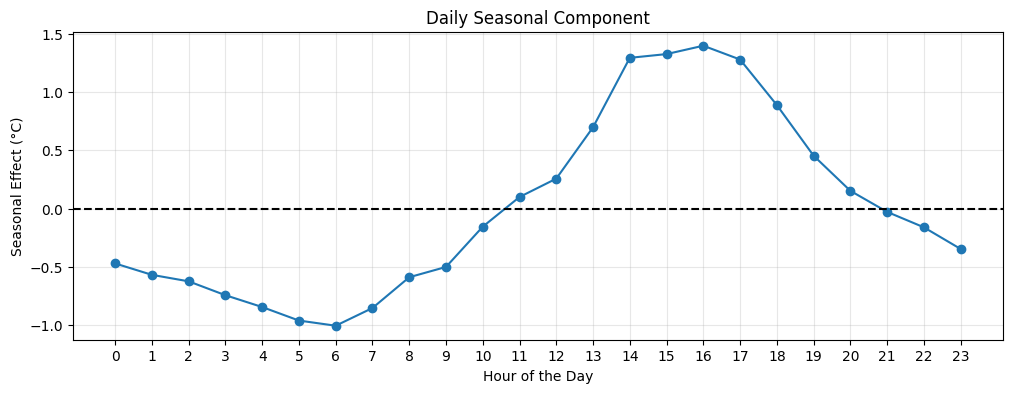

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(
    range(24),
    decomposition.seasonal.iloc[:24],
    marker='o'
)

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Daily Seasonal Component')
plt.xlabel('Hour of the Day')
plt.ylabel('Seasonal Effect (°C)')
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

In [ ]:
print("Minimum seasonal effect:",
      round(decomposition.seasonal.min(), 2))

print("Maximum seasonal effect:",
      round(decomposition.seasonal.max(), 2))

print("Remainder standard deviation:",
      round(decomposition.resid.std(), 2))

print("\nMonthly average oil temperature:")

print(ot_series.resample('MS').mean().round(2))

Minimum seasonal effect: -1.0
Maximum seasonal effect: 1.4
Remainder standard deviation: 1.19

Monthly average oil temperature:
date
2016-07-01    33.80
2016-08-01    31.15
2016-09-01    23.04
2016-10-01    17.15
2016-11-01    13.51
2016-12-01     9.58
2017-01-01     7.96
2017-02-01     8.50
2017-03-01     9.38
2017-04-01    15.42
2017-05-01    17.64
2017-06-01    18.08
2017-07-01    21.04
2017-08-01    16.15
2017-09-01    13.30
2017-10-01     9.54
2017-11-01     7.45
2017-12-01     4.42
2018-01-01     2.38
2018-02-01     3.84
2018-03-01     6.67
2018-04-01     8.23
2018-05-01    10.24
2018-06-01     9.47
Freq: MS, Name: OT, dtype: float64


### Period Selection

I selected a period of 24 because the ETTh1 dataset contains
hourly observations. Therefore, 24 observations represent
one complete daily cycle. I used additive decomposition
because the oil temperature contains negative values,
making multiplicative decomposition unsuitable.

### Seasonality

The oil temperature exhibits daily seasonality. The
seasonal component shows that the temperature is generally
lower during the early morning and higher during the
afternoon.

The minimum seasonal effect is approximately -1.00°C at
6 AM, while the maximum is approximately 1.40°C at 4 PM.

The full temperature plot also suggests yearly seasonality,
with higher temperatures during summer and lower
temperatures during winter. However, the decomposition
with a period of 24 specifically captures daily seasonality.

### Trend

The oil temperature exhibits an overall downward trend,
although there are fluctuations throughout the dataset.

For example, the average oil temperature in July 2016
was 33.80°C, compared to 21.04°C in July 2017.
Similarly, the average temperature in January 2017 was
7.96°C, compared to 2.38°C in January 2018.

These observations indicate that the temperature is
generally lower in the second year.

### Remainder

The remainder represents the temperature variations that
are not explained by the trend and daily seasonal
components. It has a standard deviation of approximately
1.19°C, indicating that some variation remains after
removing the trend and daily seasonality.

## Task 2: Feature Engineering and Splitting

In [ ]:
# Make sure data is ordered chronologically
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Remove the date column and store it separately
date_time = df.pop('date')

# Convert timestamps to seconds
timestamp_seconds = date_time.astype('int64') // 10**9

# Number of seconds in a day and a year
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_year = 365.2425 * seconds_in_a_day

# Encode daily periodicity
df['Day y'] = np.sin(
    timestamp_seconds * (2 * np.pi / seconds_in_a_day)
)

df['Day x'] = np.cos(
    timestamp_seconds * (2 * np.pi / seconds_in_a_day)
)

# Encode yearly periodicity
df['Year y'] = np.sin(
    timestamp_seconds * (2 * np.pi / seconds_in_a_year)
)

df['Year x'] = np.cos(
    timestamp_seconds * (2 * np.pi / seconds_in_a_year)
)

df.head()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,Day y,Day x,Year y,Year x
0,5.827,2.009,1.599,0.462,4.203,1.340,30.531000,-4.877283e-12,1.000000,0.013353,-0.999911
1,5.693,2.076,1.492,0.426,4.142,1.371,27.787001,2.588190e-01,0.965926,0.012637,-0.999920
2,5.157,1.741,1.279,0.355,3.777,1.218,27.787001,5.000000e-01,0.866025,0.011920,-0.999929
3,5.090,1.942,1.279,0.391,3.807,1.279,25.044001,7.071068e-01,0.707107,0.011203,-0.999937
4,5.358,1.942,1.492,0.462,3.868,1.279,21.948000,8.660254e-01,0.500000,0.010486,-0.999945


In [ ]:
print("Dataset shape:", df.shape)
print("Number of features:", df.shape[1])

df.describe().transpose()

Dataset shape: (17420, 11)
Number of features: 11


,count,mean,std,min,25%,50%,75%,max
HUFL,17420.0,7.375141,7.067744,-22.705999,5.827000,8.774000e+00,11.788000,23.643999
HULL,17420.0,2.242242,2.042342,-4.756000,0.737000,2.210000e+00,3.684000,10.114000
MUFL,17420.0,4.300239,6.826978,-25.087999,3.296000,5.970000e+00,8.635000,17.341000
MULL,17420.0,0.881568,1.809293,-5.934000,-0.284000,9.590000e-01,2.203000,7.747000
LUFL,17420.0,3.066062,1.164506,-1.188000,2.315000,2.833000e+00,3.625000,8.498000
LULL,17420.0,0.856932,0.599552,-1.371000,0.670000,9.750000e-01,1.218000,3.046000
OT,17420.0,13.324672,8.566946,-4.080000,6.964000,1.139600e+01,18.079000,46.007000
Day y,17420.0,0.000134,0.707145,-1.000000,-0.707107,2.398958e-14,0.707107,1.000000
Day x,17420.0,-0.000174,0.707109,-1.000000,-0.707107,-2.548329e-14,0.707107,1.000000
Year y,17420.0,-0.000344,0.709374,-1.000000,-0.710552,-1.000253e-02,0.710534,1.000000


### Feature Engineering

Following the lab notebook, I converted the date column
into four cyclical features: Day x, Day y, Year x and
Year y using sine and cosine transformations.

These features allow the model to learn daily and yearly
temperature patterns while maintaining the cyclical
relationship between different times.

After removing the original date column, the dataset
contains 11 numerical features.

2.3 Split the dataset

In [ ]:
# Total number of observations
n = len(df)

# First 12 months for training
num_train_samples = 12 * 30 * 24

# Next 6 months for validation
num_val_samples = 6 * 30 * 24

# Remaining observations for testing
num_test_samples = n - num_train_samples - num_val_samples

print("Number of training samples:", num_train_samples)
print("Number of validation samples:", num_val_samples)
print("Number of test samples:", num_test_samples)
print("Total samples:", n)

Number of training samples: 8640
Number of validation samples: 4320
Number of test samples: 4460
Total samples: 17420


2.4 Normalize the dataset

In [ ]:
# Preserve the original data for later analysis
df_original = df.copy()

# Calculate statistics using only training data
train_mean = df[:num_train_samples].mean(axis=0)
train_std = df[:num_train_samples].std(axis=0)

# Normalize the entire dataset using training statistics
df = (df - train_mean) / train_std

df.head()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,Day y,Day x,Year y,Year x
0,-0.363102,-0.005759,-0.630676,-0.147515,1.388494,0.875092,1.460467,-6.878984e-12,1.414132,0.019950,-1.445339
1,-0.386153,0.026294,-0.650063,-0.166202,1.328900,0.924277,1.161459,3.660042e-01,1.365946,0.018943,-1.445352
2,-0.478359,-0.133975,-0.688656,-0.203056,0.972309,0.681525,1.161459,7.070659e-01,1.224674,0.017937,-1.445365
3,-0.489885,-0.037813,-0.688656,-0.184369,1.001617,0.778309,0.862561,9.999421e-01,0.999942,0.016931,-1.445376
4,-0.443782,-0.037813,-0.650063,-0.147515,1.061212,0.778309,0.525196,1.224674e+00,0.707066,0.015924,-1.445388


In [ ]:
print("Training mean of OT:", train_mean['OT'])
print("Training standard deviation of OT:", train_std['OT'])

print("\nNormalized training mean:")
print(df[:num_train_samples].mean().round(4))

print("\nNormalized training standard deviation:")
print(df[:num_train_samples].std().round(4))

Training mean of OT: 17.1282616982271
Training standard deviation of OT: 9.177022117980968

Normalized training mean:
HUFL      0.0
HULL      0.0
MUFL      0.0
MULL     -0.0
LUFL      0.0
LULL     -0.0
OT        0.0
Day y     0.0
Day x     0.0
Year y    0.0
Year x   -0.0
dtype: float64

Normalized training standard deviation:
HUFL      1.0
HULL      1.0
MUFL      1.0
MULL      1.0
LUFL      1.0
LULL      1.0
OT        1.0
Day y     1.0
Day x     1.0
Year y    1.0
Year x    1.0
dtype: float64


### Splitting and Normalization

I split the dataset chronologically into 8,640 training
observations, 4,320 validation observations and 4,460
test observations.

I did not randomly split the data because the temporal
ordering must be preserved.

I normalized all 11 features using the mean and standard
deviation calculated exclusively from the training data
to prevent data leakage.

The original training mean and standard deviation of OT
were approximately 17.1283°C and 9.1770°C, respectively.
After normalization, the training features have a mean
of approximately zero and a standard deviation of one.

2.6 Create the TensorFlow datasets

In [ ]:
sequence_length = 120
batch_size = 256
horizon = 96

delay = sequence_length + horizon - 1

num_features = df.shape[-1]
temp_index = df.columns.get_loc('OT')

print("Sequence length:", sequence_length)
print("Horizon:", horizon)
print("Delay:", delay)
print("Number of features:", num_features)
print("Temperature index:", temp_index)

Sequence length: 120
Horizon: 96
Delay: 215
Number of features: 11
Temperature index: 6


In [ ]:
def create_datasets(sequence_length, horizon=96, batch_size=256):

    delay = sequence_length + horizon - 1

    # Split the normalized data chronologically
    train_data = df.iloc[:num_train_samples]

    val_data = df.iloc[
        num_train_samples:
        num_train_samples + num_val_samples
    ]

    test_data = df.iloc[
        num_train_samples + num_val_samples:
    ]

    def create_dataset(split_data):

        return keras.preprocessing.timeseries_dataset_from_array(
            data=split_data.iloc[:-horizon].to_numpy(
                dtype=np.float32
            ),
            targets=split_data['OT'].iloc[delay:].to_numpy(
                dtype=np.float32
            ),
            sequence_length=sequence_length,
            batch_size=batch_size,
            shuffle=False
        )

    train_dataset = create_dataset(train_data)
    val_dataset = create_dataset(val_data)
    test_dataset = create_dataset(test_data)

    return train_dataset, val_dataset, test_dataset

In [ ]:
train_dataset, val_dataset, test_dataset = create_datasets(
    sequence_length=sequence_length,
    horizon=horizon,
    batch_size=batch_size
)

In [ ]:
for samples, targets in train_dataset.take(1):
    print("Samples shape:", samples.shape)
    print("Targets shape:", targets.shape)

    print("\nFirst input sequence shape:", samples[0].shape)
    print("First target:", targets[0].numpy())

Samples shape: (256, 120, 11)
Targets shape: (256,)

First input sequence shape: (120, 11)
First target: 1.3991182


2.8 Verify the forecast horizon

In [ ]:
for samples, targets in train_dataset.take(1):

    last_input_ot = samples[0, -1, temp_index].numpy()
    target_ot = targets[0].numpy()

    # Convert normalized temperatures back to Celsius
    last_input_ot = (
        last_input_ot * train_std['OT'] + train_mean['OT']
    )

    target_ot = (
        target_ot * train_std['OT'] + train_mean['OT']
    )

    print("Input start time:", date_time.iloc[0])

    print("Input end time:",
          date_time.iloc[sequence_length - 1])

    print("Target time:", date_time.iloc[delay])

    print("Forecast interval:",
          date_time.iloc[delay] -
          date_time.iloc[sequence_length - 1])

    print("Last input OT:", round(last_input_ot, 3))
    print("Target OT:", round(target_ot, 3))

Input start time: 2016-07-01 00:00:00
Input end time: 2016-07-05 23:00:00
Target time: 2016-07-09 23:00:00
Forecast interval: 4 days 00:00:00
Last input OT: 30.46
Target OT: 29.968


2.9 Count the generated sequences

In [ ]:
def count_sequences(dataset):
    return sum(samples.shape[0] for samples, targets in dataset)

print("Training sequences:", count_sequences(train_dataset))
print("Validation sequences:", count_sequences(val_dataset))
print("Testing sequences:", count_sequences(test_dataset))

# compare with 2.3 215 starting positions we loose at the end

Training sequences: 8425
Validation sequences: 4105
Testing sequences: 4245


### Preparing Time Series Datasets

I used the Keras timeseries_dataset_from_array function
to convert the normalized data into supervised learning
datasets.

I selected a sequence length of 120 hours, a forecast
horizon of 96 hours and a batch size of 256.

The target delay was calculated as:

delay = 120 + 96 - 1 = 215

For the first sequence, observations at indices 0 to 119
are used to predict the oil temperature at index 215.

Each batch contains input tensors of shape (256, 120, 11)
and target tensors of shape (256,).

I created windows separately within each data split to
prevent targets from crossing dataset boundaries. This
resulted in 8,425 training sequences, 4,105 validation
sequences and 4,245 test sequences.

I also created a reusable dataset generation function
so that I can experiment with different sequence lengths
when tuning the recurrent models.

## Task 3: Common-sense Baseline

3.2 Reverse the normalization

In [ ]:
def unnormalize(preds, targets, mean, std):
    preds = preds * std + mean
    targets = targets * std + mean

    return preds, targets

3.3 Implement the baseline and evaluation function

In [ ]:
def evaluate_model(dataset, model=None):

    total_abs_err = 0.
    num_sequences = 0

    # Index of the oil temperature feature
    temp_index = df.columns.get_loc('OT')

    for samples, targets in dataset:

        # Common-sense baseline
        if model is None:
            preds = samples[:, -1, temp_index]

        # Machine learning model
        else:
            preds = model.predict(samples, verbose=0).flatten()

        # Convert predictions and targets back to Celsius
        preds, targets = unnormalize(
            preds,
            targets,
            train_mean.iloc[temp_index],
            train_std.iloc[temp_index]
        )

        # Calculate total absolute error
        total_abs_err += np.sum(np.abs(preds - targets))

        # Count the number of sequences
        num_sequences += samples.shape[0]

    return total_abs_err / num_sequences

3.5 Evaluate the baseline

In [ ]:
baseline_mae = evaluate_model(val_dataset)

print(f"Validation MAE Baseline: {baseline_mae:.2f} °C")

Validation MAE Baseline: 2.66 °C


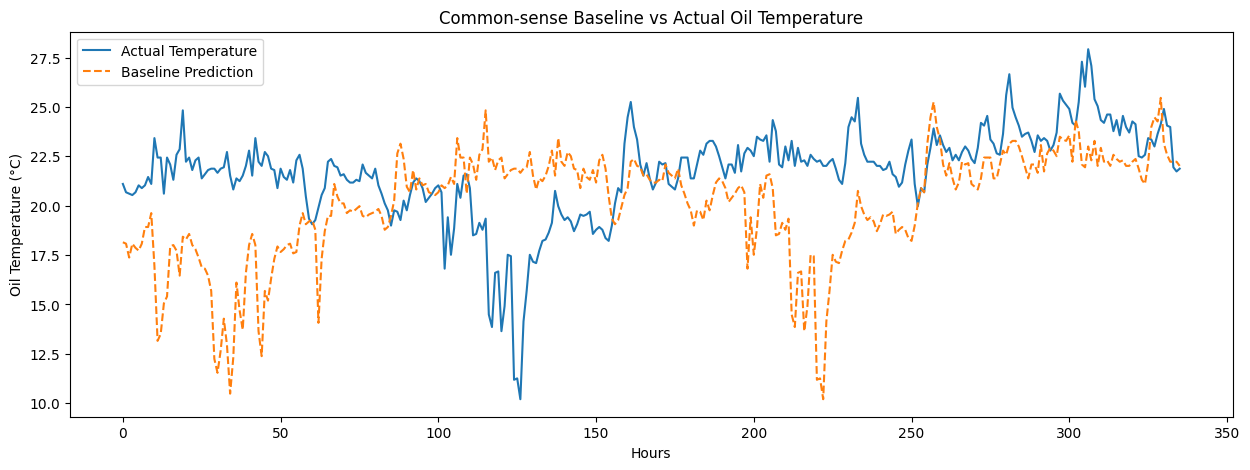

In [ ]:
baseline_predictions = []
actual_temperatures = []

for samples, targets in val_dataset:

    preds = samples[:, -1, temp_index]

    preds, targets = unnormalize(
        preds,
        targets,
        train_mean['OT'],
        train_std['OT']
    )

    baseline_predictions.extend(preds.numpy())
    actual_temperatures.extend(targets.numpy())

baseline_predictions = np.array(baseline_predictions)
actual_temperatures = np.array(actual_temperatures)

# Plot the first two weeks
hours = 14 * 24

plt.figure(figsize=(15, 5))

plt.plot(
    actual_temperatures[:hours],
    label='Actual Temperature'
)

plt.plot(
    baseline_predictions[:hours],
    label='Baseline Prediction',
    linestyle='--'
)

plt.title('Common-sense Baseline vs Actual Oil Temperature')
plt.xlabel('Hours')
plt.ylabel('Oil Temperature (°C)')
plt.legend()
plt.show()

### Common-sense Baseline

Following the approach used in the lab, I implemented a
common-sense baseline that predicts the oil temperature
96 hours into the future using the last observed oil
temperature in each input sequence.

Since the data was normalized, I reversed the
normalization using the training mean and standard
deviation before calculating the MAE.

The baseline achieved a validation MAE of 2.66°C
across 4,105 validation sequences. This means that
the predictions differ from the actual oil temperature
by approximately 2.66°C on average.

This approach does not require any training or learnable
parameters. However, it does not account for changes
in temperature or electrical load conditions.

The baseline serves as a benchmark for evaluating
the performance of the recurrent and convolutional
models in the following tasks.

## Task 4: Recurrent Models (LSTM and Hyperparameter Tuning)

In [ ]:
def build_lstm(sequence_length, num_features):

    inputs = keras.Input(
        shape=(sequence_length, num_features)
    )

    x = layers.LSTM(16)(inputs)

    outputs = layers.Dense(1)(x)

    lstm_model = keras.Model(inputs, outputs)

    return lstm_model

In [ ]:
keras.utils.set_random_seed(42)

lstm_model = build_lstm(
    sequence_length=120,
    num_features=num_features
)

lstm_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 120, 11)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,809 (7.07 KB)

 Trainable params: 1,809 (7.07 KB)

 Non-trainable params: 0 (0.00 B)

4.4 Create a reusable training function

In [ ]:
results = []
histories = {}

In [ ]:
def train_lstm(experiment_name,
               sequence_length,
               optimizer_name="rmsprop",
               use_lr_schedule=False,
               early_stopping_patience=10):

    # Reset Keras and random seed
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    # Create datasets
    train_ds, val_ds, _ = create_datasets(
        sequence_length=sequence_length,
        horizon=96,
        batch_size=256
    )

    # Build a fresh model
    model = build_lstm(sequence_length, num_features)

    # Select optimizer
    if optimizer_name == "adamw":
        optimizer = keras.optimizers.AdamW(
            learning_rate=0.001,
            weight_decay=0.0001
        )
    else:
        optimizer = keras.optimizers.RMSprop(
            learning_rate=0.001
        )

    # Save best model
    model_path = f"{experiment_name}_P10.keras"

    checkpoint = keras.callbacks.ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True
    )

    # Updated early stopping
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=early_stopping_patience,
        min_delta=1e-4,
        restore_best_weights=True
    )

    callbacks = [checkpoint, early_stopping]

    # Optional learning rate scheduling
    if use_lr_schedule:

        rop = keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.1,
            patience=3
        )

        callbacks.append(rop)

    # Compile model
    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    # Train model
    history = model.fit(
        train_ds,
        epochs=50,
        validation_data=val_ds,
        callbacks=callbacks
    )

    # Load best checkpoint
    model = keras.models.load_model(model_path)

    # Full validation MAE
    val_mae = evaluate_model(val_ds, model=model)

    # Common validation timestamps
    common_val_ds = val_ds.unbatch().skip(
        336 - sequence_length
    ).batch(256)

    common_mae = evaluate_model(
        common_val_ds,
        model=model
    )

    # Store results
    results.append({
        "Experiment": experiment_name,
        "Sequence Length": sequence_length,
        "Optimizer": optimizer_name,
        "LR Schedule": use_lr_schedule,
        "Early Stopping Patience": early_stopping_patience,
        "Epochs": len(history.history["loss"]),
        "Best Epoch": np.argmin(
            history.history["val_loss"]
        ) + 1,
        "Validation MAE": float(val_mae),
        "Common Validation MAE": float(common_mae),
        "Model Path": model_path
    })

    histories[experiment_name] = history.history

    print(f"\nValidation MAE: {val_mae:.4f} °C")
    print(f"Common Validation MAE: {common_mae:.4f} °C")

    return model

In [ ]:
def plot_history(experiment_name):

    history = histories[experiment_name]

    loss = history["loss"]
    val_loss = history["val_loss"]

    epochs = range(1, len(loss) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(epochs, loss, "bo",
             label="Training loss")

    plt.plot(epochs, val_loss, "b",
             label="Validation loss")

    plt.title(f"Training and Validation Loss - {experiment_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE)")
    plt.legend()
    plt.show()

4.5 Experiment A — Initial LSTM

In [ ]:
lstm_model_A = train_lstm(
    experiment_name="Experiment_A",
    sequence_length=120,
    optimizer_name="rmsprop",
    use_lr_schedule=False
)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - loss: 0.4838 - mae: 0.5333 - val_loss: 0.3101 - val_mae: 0.4740
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.2916 - mae: 0.4094 - val_loss: 0.2579 - val_mae: 0.4230
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.2243 - mae: 0.3638 - val_loss: 0.2471 - val_mae: 0.4109
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.1982 - mae: 0.3450 - val_loss: 0.2498 - val_mae: 0.4157
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.1838 - mae: 0.3338 - val_loss: 0.2569 - val_mae: 0.4251
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1746 - mae: 0.3259 - val_loss: 0.2667 - val_mae: 0.4365
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.1687 - mae: 0.3207 - val_loss: 0.2783 - val_mae: 0.4485
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.1642 - mae: 0.3164 - val_loss: 0.2912 - val_mae: 0.4612
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.160

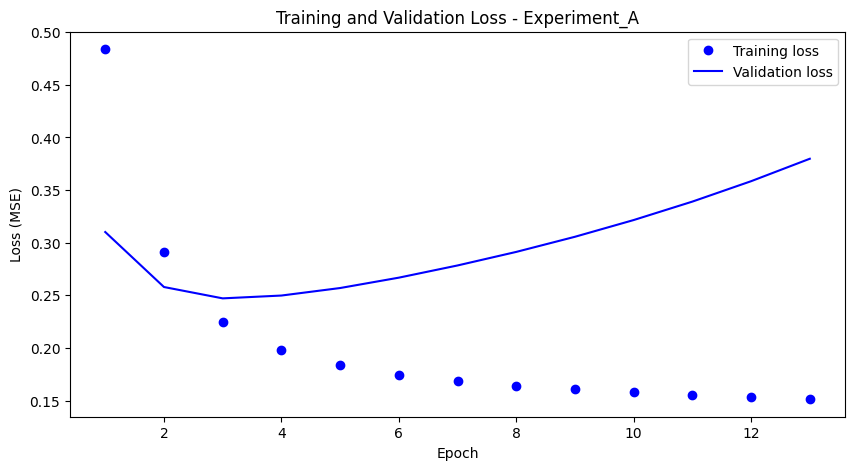

In [ ]:
plot_history("Experiment_A")

Experiment B — Sequence length 48

In [ ]:
lstm_model_B = train_lstm(
    experiment_name="Experiment_B",
    sequence_length=48,
    optimizer_name="rmsprop",
    use_lr_schedule=False
)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 0.4932 - mae: 0.5395 - val_loss: 0.3168 - val_mae: 0.4776
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.2956 - mae: 0.4129 - val_loss: 0.2645 - val_mae: 0.4264
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.2244 - mae: 0.3645 - val_loss: 0.2543 - val_mae: 0.4141
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - loss: 0.1976 - mae: 0.3450 - val_loss: 0.2594 - val_mae: 0.4208
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - loss: 0.1835 - mae: 0.3337 - val_loss: 0.2679 - val_mae: 0.4315
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.1740 - mae: 0.3253 - val_loss: 0.2784 - val_mae: 0.4435
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.1671 - mae: 0.3186 - val_loss: 0.2915 - val_mae: 0.4568
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.1617 - mae: 0.3132 - val_loss: 0.3071 - val_mae: 0.4712
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.157

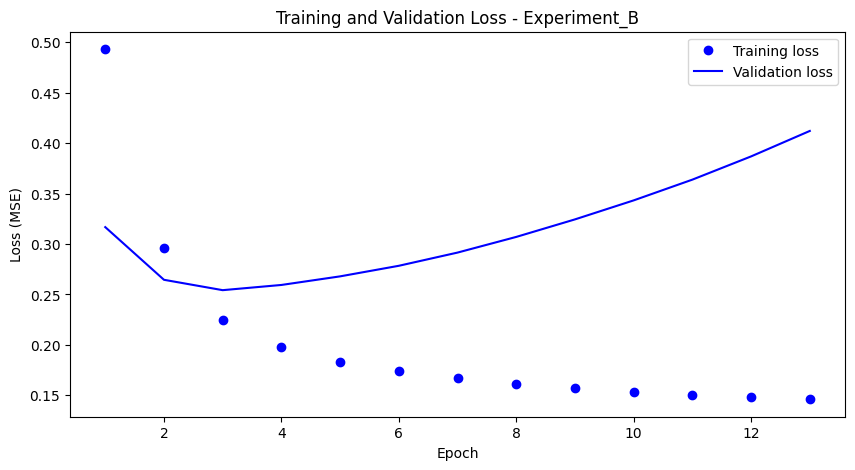

In [ ]:
plot_history("Experiment_B")

Experiment C — Sequence length 96

In [ ]:
lstm_model_C = train_lstm(
    experiment_name="Experiment_C",
    sequence_length=96,
    optimizer_name="rmsprop",
    use_lr_schedule=False
)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 0.4865 - mae: 0.5354 - val_loss: 0.3115 - val_mae: 0.4737
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - loss: 0.2922 - mae: 0.4104 - val_loss: 0.2611 - val_mae: 0.4233
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.2230 - mae: 0.3635 - val_loss: 0.2532 - val_mae: 0.4132
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1973 - mae: 0.3450 - val_loss: 0.2577 - val_mae: 0.4197
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.1839 - mae: 0.3346 - val_loss: 0.2654 - val_mae: 0.4301
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1753 - mae: 0.3270 - val_loss: 0.2754 - val_mae: 0.4420
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1695 - mae: 0.3217 - val_loss: 0.2872 - val_mae: 0.4545
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.1651 - mae: 0.3173 - val_loss: 0.3000 - val_mae: 0.4673
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - loss: 0.161

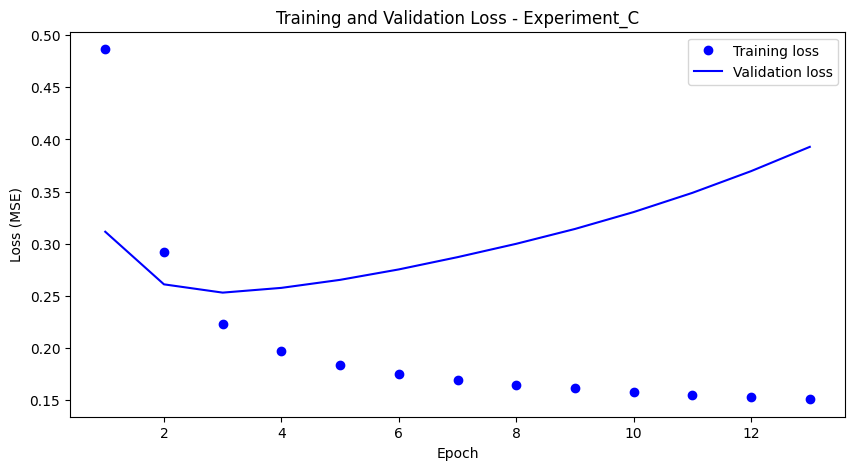

In [ ]:
plot_history("Experiment_C")

Experiment D — Sequence length 336

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 0.4697 - mae: 0.5249 - val_loss: 0.3222 - val_mae: 0.4851
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.2947 - mae: 0.4076 - val_loss: 0.2716 - val_mae: 0.4338
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.2306 - mae: 0.3645 - val_loss: 0.2650 - val_mae: 0.4236
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.2050 - mae: 0.3472 - val_loss: 0.2719 - val_mae: 0.4317
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 0.1912 - mae: 0.3375 - val_loss: 0.2825 - val_mae: 0.4442
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - loss: 0.1820 - mae: 0.3308 - val_loss: 0.2946 - val_mae: 0.4579
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.1758 - mae: 0.3263 - val_loss: 0.3080 - val_mae: 0.4719
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.1708 - mae: 0.3221 - val_loss: 0.3222 - val_mae: 0.4860
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.166

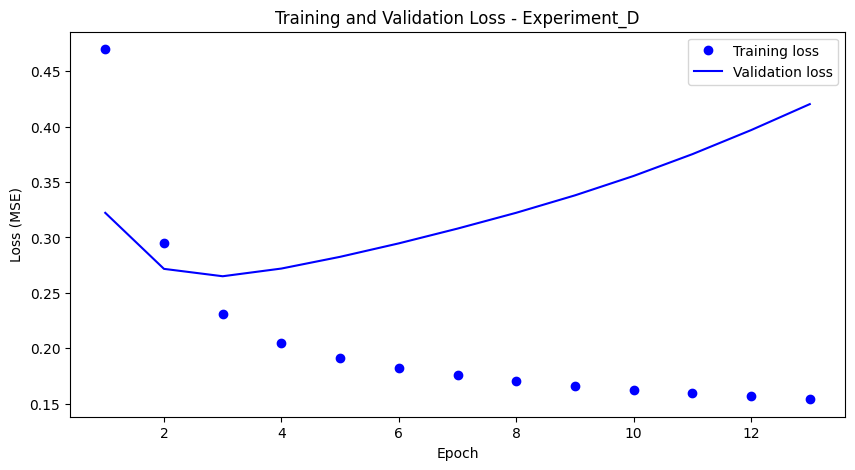

In [ ]:
lstm_model_D = train_lstm(
    experiment_name="Experiment_D",
    sequence_length=336,
    optimizer_name="rmsprop",
    use_lr_schedule=False
)

plot_history("Experiment_D")

Identify the best sequence length

In [ ]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values("Common Validation MAE")
)

,Experiment,Sequence Length,Optimizer,LR Schedule,Early Stopping Patience,Epochs,Best Epoch,Validation MAE,Common Validation MAE,Model Path
0,Experiment_A,120,rmsprop,False,10,13,3,3.771138,3.822886,Experiment_A_P10.keras
1,Experiment_B,48,rmsprop,False,10,13,3,3.799896,3.868725,Experiment_B_P10.keras
2,Experiment_C,96,rmsprop,False,10,13,3,3.791942,3.881220,Experiment_C_P10.keras
3,Experiment_D,336,rmsprop,False,10,13,3,3.887244,3.887244,Experiment_D_P10.keras


In [ ]:
best_length_result = min(
    results,
    key=lambda x: x["Common Validation MAE"]
)

best_sequence_length = best_length_result["Sequence Length"]

print("Best experiment:",
      best_length_result["Experiment"])

print("Best sequence length:",
      best_sequence_length)

print("Best common validation MAE:",
      best_length_result["Common Validation MAE"])

Best experiment: Experiment_A
Best sequence length: 120
Best common validation MAE: 3.8228862285614014


4.7 Experiment E — Learning rate schedule

In [ ]:
keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", #Observe validation loss.
    factor=0.1, #Wait for three epochs without improvement.
    patience=3 #Reduce the learning rate to one-tenth of its current value.
)

In [ ]:
lstm_model_E = train_lstm(
    experiment_name="Experiment_E",
    sequence_length=best_sequence_length,
    optimizer_name="rmsprop",
    use_lr_schedule=True
)



Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - loss: 0.4838 - mae: 0.5333 - val_loss: 0.3101 - val_mae: 0.4740 - learning_rate: 0.0010
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.2916 - mae: 0.4094 - val_loss: 0.2579 - val_mae: 0.4230 - learning_rate: 0.0010
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.2243 - mae: 0.3638 - val_loss: 0.2471 - val_mae: 0.4109 - learning_rate: 0.0010
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.1982 - mae: 0.3450 - val_loss: 0.2498 - val_mae: 0.4157 - learning_rate: 0.0010
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.1838 - mae: 0.3338 - val_loss: 0.2569 - val_mae: 0.4251 - learning_rate: 0.0010
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1746 - mae: 0.3259 - val_loss: 0.2667 - val_mae: 0.4365 - learning_rate: 0.0010
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.1687 - mae: 0.3200 - val_loss: 0.2721 - val_mae: 0.4410 - learning_rate: 1.0000e-04
Epoch 8/5

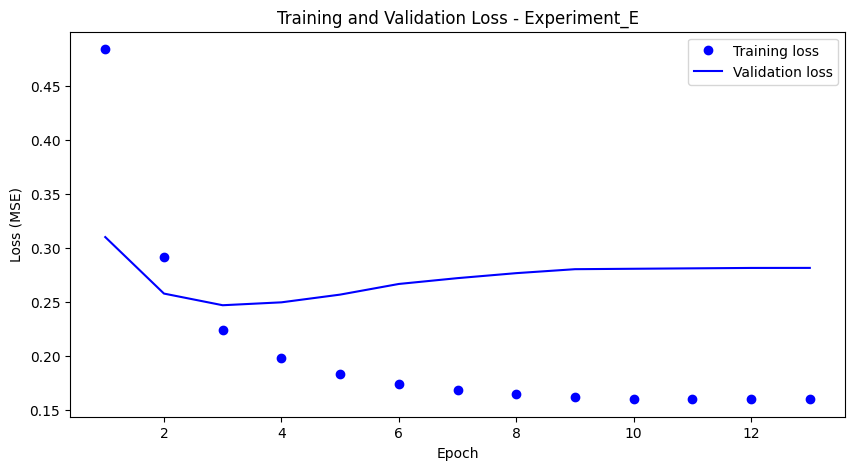

In [ ]:
plot_history("Experiment_E")

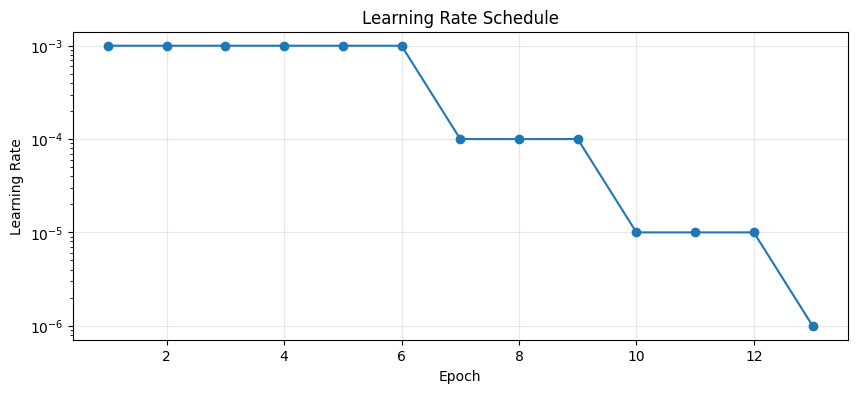

In [ ]:
learning_rates = histories[
    "Experiment_E"
].get("learning_rate")

if learning_rates is not None:

    plt.figure(figsize=(10, 4))

    plt.plot(
        range(1, len(learning_rates) + 1),
        learning_rates,
        marker="o"
    )

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Learning Rate")
    plt.title("Learning Rate Schedule")
    plt.grid(alpha=0.3)
    plt.show()

4.8 Experiment F — AdamW optimizer

In [ ]:
best_config = min(
    results,
    key=lambda x: x["Common Validation MAE"]
)

best_sequence_length = best_config["Sequence Length"]
best_lr_schedule = best_config["LR Schedule"]

print("Best configuration so far:")
print(best_config)

Best configuration so far:
{'Experiment': 'Experiment_A', 'Sequence Length': 120, 'Optimizer': 'rmsprop', 'LR Schedule': False, 'Early Stopping Patience': 10, 'Epochs': 13, 'Best Epoch': np.int64(3), 'Validation MAE': 3.7711384296417236, 'Common Validation MAE': 3.8228862285614014, 'Model Path': 'Experiment_A_P10.keras'}


In [ ]:
lstm_model_F = train_lstm(
    experiment_name="Experiment_F",
    sequence_length=best_sequence_length,
    optimizer_name="adamw",
    use_lr_schedule=best_lr_schedule
)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 0.5779 - mae: 0.5941 - val_loss: 0.3688 - val_mae: 0.5154
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.3139 - mae: 0.4306 - val_loss: 0.3032 - val_mae: 0.4598
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.2290 - mae: 0.3671 - val_loss: 0.2784 - val_mae: 0.4339
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - loss: 0.1955 - mae: 0.3417 - val_loss: 0.2704 - val_mae: 0.4282
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.1792 - mae: 0.3291 - val_loss: 0.2711 - val_mae: 0.4328
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.1696 - mae: 0.3206 - val_loss: 0.2768 - val_mae: 0.4415
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.1627 - mae: 0.3140 - val_loss: 0.2843 - val_mae: 0.4511
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.1582 - mae: 0.3092 - val_loss: 0.2961 - val_mae: 0.4635
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.154

Experiment G — AdamW + Learning Rate Scheduling (120 hours)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.5779 - mae: 0.5941 - val_loss: 0.3688 - val_mae: 0.5154 - learning_rate: 0.0010
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.3139 - mae: 0.4306 - val_loss: 0.3032 - val_mae: 0.4598 - learning_rate: 0.0010
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.2290 - mae: 0.3671 - val_loss: 0.2784 - val_mae: 0.4339 - learning_rate: 0.0010
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1955 - mae: 0.3417 - val_loss: 0.2704 - val_mae: 0.4282 - learning_rate: 0.0010
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - loss: 0.1792 - mae: 0.3291 - val_loss: 0.2711 - val_mae: 0.4328 - learning_rate: 0.0010
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 0.1696 - mae: 0.3206 - val_loss: 0.2768 - val_mae: 0.4415 - learning_rate: 0.0010
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.1627 - mae: 0.3140 - val_loss: 0.2843 - val_mae: 0.4511 - learning_rate: 0.0010
Epoch 8/50
33

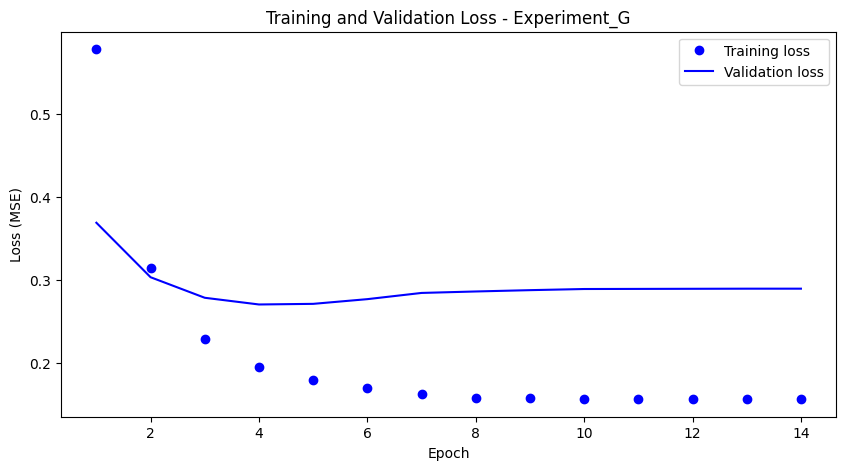

In [ ]:
lstm_model_G = train_lstm(
    experiment_name="Experiment_G",
    sequence_length=120,
    optimizer_name="adamw",
    use_lr_schedule=True
)

plot_history("Experiment_G")

In [ ]:
results_df = pd.DataFrame(results)

display(
      results_df.drop(columns=["Model Path"])
    .sort_values("Common Validation MAE")
    .round(4)
)

,Experiment,Sequence Length,Optimizer,LR Schedule,Early Stopping Patience,Epochs,Best Epoch,Validation MAE,Common Validation MAE
0,Experiment_A,120,rmsprop,False,10,13,3,3.7711,3.8229
4,Experiment_E,120,rmsprop,True,10,13,3,3.7711,3.8229
1,Experiment_B,48,rmsprop,False,10,13,3,3.7999,3.8687
2,Experiment_C,96,rmsprop,False,10,13,3,3.7919,3.8812
3,Experiment_D,336,rmsprop,False,10,13,3,3.8872,3.8872
5,Experiment_F,120,adamw,False,10,14,4,3.9295,3.9848
6,Experiment_G,120,adamw,True,10,14,4,3.9295,3.9848


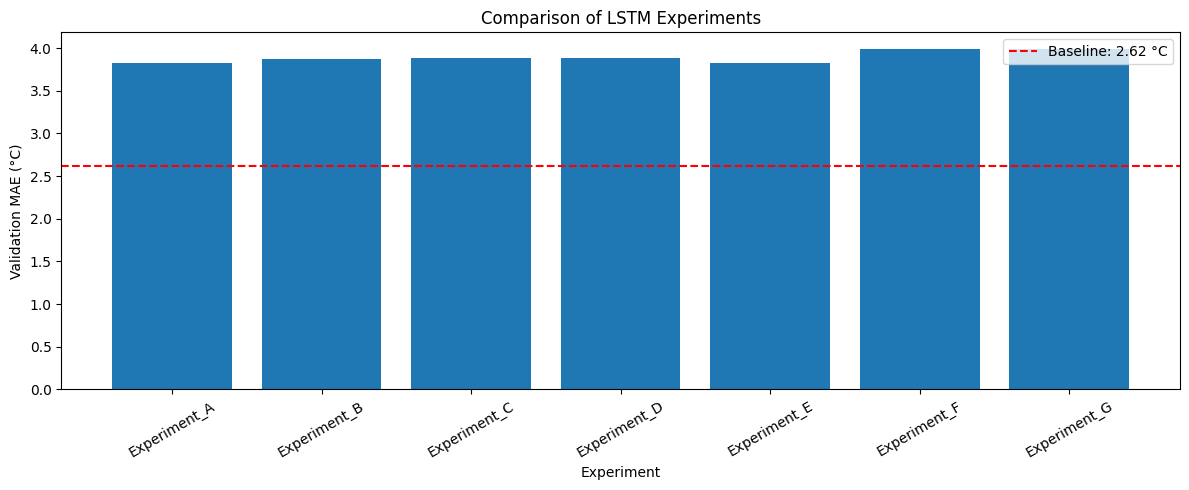

In [ ]:
# Create baseline with the same validation timestamps
_, common_baseline_ds, _ = create_datasets(
    sequence_length=336
)

common_baseline_mae = evaluate_model(common_baseline_ds)

plt.figure(figsize=(12, 5))

plt.bar(
    results_df["Experiment"],
    results_df["Common Validation MAE"]
)

plt.axhline(
    y=common_baseline_mae,
    color="red",
    linestyle="--",
    label=f"Baseline: {common_baseline_mae:.2f} °C"
)

plt.title("Comparison of LSTM Experiments")
plt.xlabel("Experiment")
plt.ylabel("Validation MAE (°C)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
best_result = min(
    results,
    key=lambda x: x["Common Validation MAE"]
)

best_lstm_model = keras.models.load_model(
    best_result["Model Path"]
)

best_sequence_length = best_result["Sequence Length"]
best_optimizer = best_result["Optimizer"]
best_lr_schedule = best_result["LR Schedule"]
best_lstm_mae = best_result["Validation MAE"]

best_lstm_model.save("best_lstm.keras")

print("Best experiment:", best_result["Experiment"])
print("Sequence length:", best_sequence_length)
print("Optimizer:", best_optimizer)
print("LR schedule:", best_lr_schedule)
print("Validation MAE:", best_lstm_mae)
print("Common validation MAE:",
      best_result["Common Validation MAE"])

Best experiment: Experiment_A
Sequence length: 120
Optimizer: rmsprop
LR schedule: False
Validation MAE: 3.7711384296417236
Common validation MAE: 3.8228862285614014


In [ ]:
best_train_dataset, best_val_dataset, best_test_dataset = (
    create_datasets(
        sequence_length=best_sequence_length,
        horizon=96,
        batch_size=256
    )
)

### Recurrent Models

Following the lab notebook, I implemented a recurrent
model consisting of an LSTM layer with 16 hidden units
and a Dense output layer with one neuron.

The model contains 1,809 trainable parameters and uses
MSE as the loss function.

I performed six experiments to investigate the effect
of sequence length, learning rate scheduling and the
AdamW optimizer.

To ensure a controlled comparison, I changed one
configuration at a time while keeping the architecture,
forecast horizon, batch size and maximum number of
epochs constant.

I also reset the random seed before each experiment
and compared the models on common validation timestamps.

### Experiment G: AdamW with Learning Rate Scheduling

In this additional experiment, I used the original sequence
length of 120 hours with the AdamW optimizer and learning
rate scheduling.

The goal was to investigate whether combining adaptive
learning rate reduction and decoupled weight decay improves
the forecasting performance of the original LSTM configuration.

All other training parameters and the model architecture
were kept unchanged.

In [ ]:
for exp in ["Experiment_A", "Experiment_E",
            "Experiment_F", "Experiment_G"]:

    history = histories[exp]

    print(exp)

    print("Best epoch:",
          np.argmin(history["val_loss"]) + 1)

    print("Learning rates:",
          history.get("learning_rate", "Not recorded"))

    print("Best validation loss:",
          min(history["val_loss"]))

    print()

Experiment_A
Best epoch: 3
Learning rates: Not recorded
Best validation loss: 0.24708284437656403

Experiment_E
Best epoch: 3
Learning rates: [0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.00010000000474974513, 0.00010000000474974513, 0.00010000000474974513, 1.0000000656873453e-05, 1.0000000656873453e-05, 1.0000000656873453e-05, 1.0000001111620804e-06]
Best validation loss: 0.24708284437656403

Experiment_F
Best epoch: 4
Learning rates: Not recorded
Best validation loss: 0.2703554928302765

Experiment_G
Best epoch: 4
Learning rates: [0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.00010000000474974513, 0.00010000000474974513, 0.00010000000474974513, 1.0000000656873453e-05, 1.0000000656873453e-05, 1.0000000656873453e-05, 1.0000001111620804e-06]
Best validation loss: 0.2703554928302

In [ ]:
previous_results_df = pd.DataFrame(results).copy()
previous_histories = histories.copy()

results = []
histories = {}

## 5.3 Build the 1D convolutional model

In [ ]:
def build_1dconv(sequence_length, num_features,
                 kernel_size=24):

    inputs = keras.Input(
        shape=(sequence_length, num_features)
    )

    x = layers.Conv1D(
        8, kernel_size, activation="relu"
    )(inputs)

    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(
        8, kernel_size // 2, activation="relu"
    )(x)

    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(
        8, kernel_size // 4, activation="relu"
    )(x)

    x = layers.GlobalAveragePooling1D()(x)

    outputs = layers.Dense(1)(x)

    model = keras.Model(inputs, outputs)

    return model

In [ ]:
keras.utils.set_random_seed(42)

conv1D_model = build_1dconv(
    sequence_length=120,
    num_features=num_features,
    kernel_size=24
)

conv1D_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 120, 11)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 97, 8)          │         2,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,297 (12.88 KB)

 Trainable params: 3,297 (12.88 KB)

 Non-trainable params: 0 (0.00 B)

## 5.5 Create a reusable CNN training function

In [ ]:
cnn_results = []
cnn_histories = {}

In [ ]:
def train_cnn(experiment_name, kernel_size):

    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    # Use the same sequence length as the best LSTM
    train_ds, val_ds, _ = create_datasets(
        sequence_length=120,
        horizon=96,
        batch_size=256
    )

    # Build a fresh CNN
    model = build_1dconv(
        sequence_length=120,
        num_features=num_features,
        kernel_size=kernel_size
    )

    model_path = f"{experiment_name}.keras"

    checkpoint = keras.callbacks.ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=1e-4,
        restore_best_weights=True
    )

    model.compile(
        optimizer=keras.optimizers.RMSprop(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    history = model.fit(
        train_ds,
        epochs=50,
        validation_data=val_ds,
        callbacks=[checkpoint, early_stopping]
    )

    # Load best checkpoint
    model = keras.models.load_model(model_path)

    # Full validation MAE
    val_mae = evaluate_model(val_ds, model=model)

    # Common validation timestamps from Task 4
    common_val_ds = val_ds.unbatch().skip(
        336 - 120
    ).batch(256)

    common_mae = evaluate_model(
        common_val_ds,
        model=model
    )

    # Store results
    cnn_results.append({
        "Experiment": experiment_name,
        "Sequence Length": 120,
        "Kernel 1": kernel_size,
        "Kernel 2": kernel_size // 2,
        "Kernel 3": kernel_size // 4,
        "Parameters": model.count_params(),
        "Epochs": len(history.history["loss"]),
        "Best Epoch": np.argmin(
            history.history["val_loss"]
        ) + 1,
        "Validation MAE": float(val_mae),
        "Common Validation MAE": float(common_mae),
        "Model Path": model_path
    })

    cnn_histories[experiment_name] = history.history

    print(f"\nValidation MAE: {val_mae:.4f} °C")
    print(f"Common Validation MAE: {common_mae:.4f} °C")

    return model

In [ ]:
def plot_cnn_history(experiment_name):

    history = cnn_histories[experiment_name]

    loss = history["loss"]
    val_loss = history["val_loss"]

    epochs = range(1, len(loss) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(
        epochs, loss, "bo",
        label="Training loss"
    )

    plt.plot(
        epochs, val_loss, "b",
        label="Validation loss"
    )

    plt.title(
        f"Training and Validation Loss - {experiment_name}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE)")
    plt.legend()
    plt.show()

Experiment CNN A — Original lab configuration

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - loss: 0.7534 - mae: 0.7058 - val_loss: 0.9716 - val_mae: 0.8646
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.5450 - mae: 0.5903 - val_loss: 0.8903 - val_mae: 0.8214
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.5108 - mae: 0.5769 - val_loss: 0.8433 - val_mae: 0.7956
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.4759 - mae: 0.5572 - val_loss: 0.7864 - val_mae: 0.7702
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.4530 - mae: 0.5411 - val_loss: 0.6963 - val_mae: 0.7170
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4316 - mae: 0.5264 - val_loss: 0.6507 - val_mae: 0.6866
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.4116 - mae: 0.5124 - val_loss: 0.6046 - val_mae: 0.6537
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.3939 - mae: 0.5003 - val_loss: 0.5755 - val_mae: 0.6337
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.37

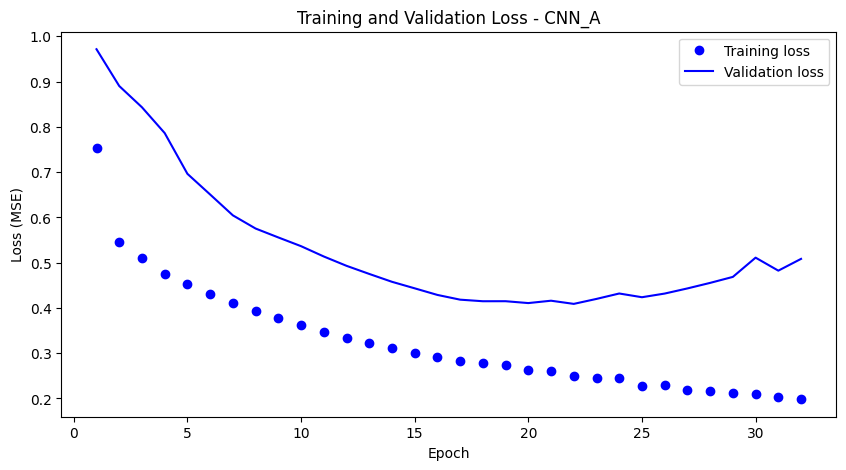

In [ ]:
cnn_model_A = train_cnn(
    experiment_name="CNN_A",
    kernel_size=24
)

plot_cnn_history("CNN_A")

Experiment CNN B — Smaller kernel

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - loss: 0.8186 - mae: 0.7482 - val_loss: 0.9292 - val_mae: 0.8206
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.6168 - mae: 0.6299 - val_loss: 0.7968 - val_mae: 0.7652
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.5084 - mae: 0.5708 - val_loss: 0.7386 - val_mae: 0.7429
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4370 - mae: 0.5297 - val_loss: 0.6601 - val_mae: 0.7000
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.3364 - mae: 0.4612 - val_loss: 0.5421 - val_mae: 0.6329
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.2397 - mae: 0.3798 - val_loss: 0.4206 - val_mae: 0.5577
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - loss: 0.2130 - mae: 0.3536 - val_loss: 0.3632 - val_mae: 0.5169
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.2059 - mae: 0.3492 - val_loss: 0.3393 - val_mae: 0.4987
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.20

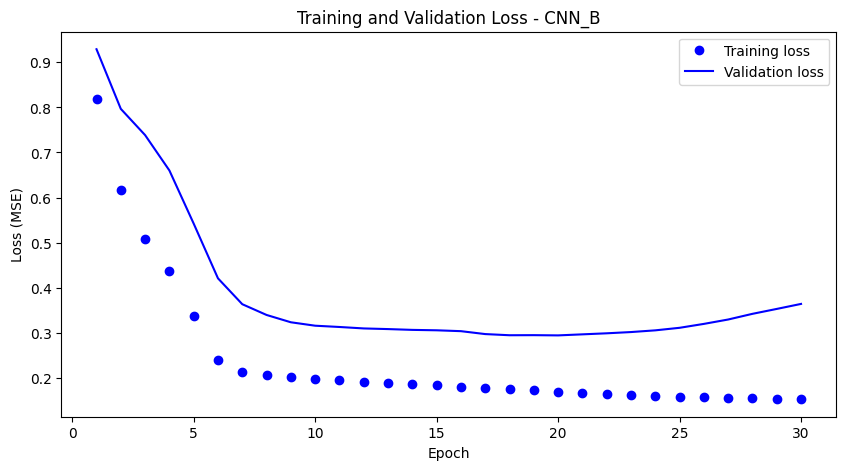

In [ ]:
cnn_model_B = train_cnn(
    experiment_name="CNN_B",
    kernel_size=12
)

plot_cnn_history("CNN_B")

Experiment CNN C — Shortest kernel

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 1.2206 - mae: 0.9534 - val_loss: 1.1875 - val_mae: 0.9386
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.7965 - mae: 0.7363 - val_loss: 0.9256 - val_mae: 0.8173
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 0.6089 - mae: 0.6296 - val_loss: 0.8117 - val_mae: 0.7702
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.5126 - mae: 0.5731 - val_loss: 0.7519 - val_mae: 0.7458
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.4686 - mae: 0.5503 - val_loss: 0.7036 - val_mae: 0.7213
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.4431 - mae: 0.5362 - val_loss: 0.6644 - val_mae: 0.6984
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.4216 - mae: 0.5231 - val_loss: 0.6337 - val_mae: 0.6797
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4026 - mae: 0.5106 - val_loss: 0.6056 - val_mae: 0.6624
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.385

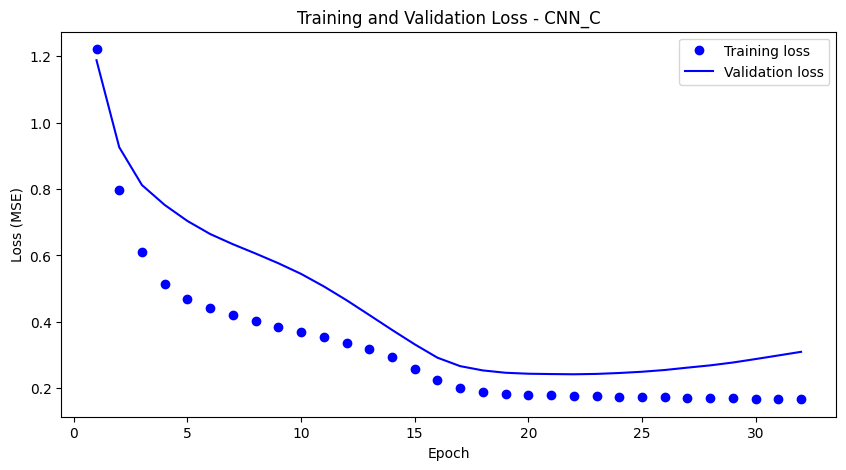

In [ ]:
cnn_model_C = train_cnn(
    experiment_name="CNN_C",
    kernel_size=8
)

plot_cnn_history("CNN_C")

Experiment CNN D — Larger kernel

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - loss: 0.6601 - mae: 0.6532 - val_loss: 0.7108 - val_mae: 0.7173
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.4530 - mae: 0.5344 - val_loss: 0.5228 - val_mae: 0.6109
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.3227 - mae: 0.4252 - val_loss: 0.3847 - val_mae: 0.5266
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 0.2717 - mae: 0.3909 - val_loss: 0.3283 - val_mae: 0.4883
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.2582 - mae: 0.3837 - val_loss: 0.2952 - val_mae: 0.4624
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.2417 - mae: 0.3732 - val_loss: 0.2914 - val_mae: 0.4608
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.2303 - mae: 0.3659 - val_loss: 0.2928 - val_mae: 0.4621
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.2186 - mae: 0.3588 - val_loss: 0.2994 - val_mae: 0.4688
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.219

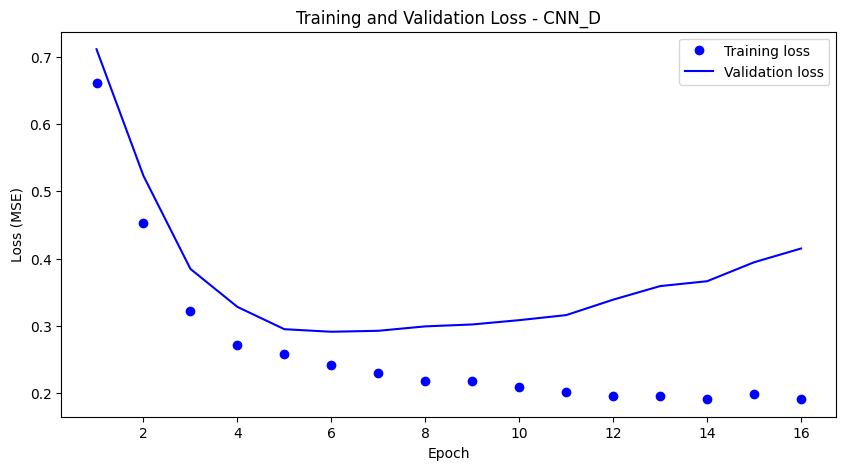

In [ ]:
cnn_model_D = train_cnn(
    experiment_name="CNN_D",
    kernel_size=32
)

plot_cnn_history("CNN_D")

 Display the experiment results

In [ ]:
cnn_results_df = pd.DataFrame(cnn_results)

display(
    cnn_results_df
    .drop(columns=["Model Path"])
    .sort_values("Common Validation MAE")
    .round(4)
)

,Experiment,Sequence Length,Kernel 1,Kernel 2,Kernel 3,Parameters,Epochs,Best Epoch,Validation MAE,Common Validation MAE
2,CNN_C,120,8,4,2,1121,32,22,3.7597,3.8461
3,CNN_D,120,32,16,8,4385,16,6,4.2292,4.3373
1,CNN_B,120,12,6,3,1665,30,20,4.2167,4.3395
0,CNN_A,120,24,12,6,3297,32,22,4.9785,5.1154


Select and save the best convolutional model

In [ ]:
best_cnn_result = min(
    cnn_results,
    key=lambda x: x["Common Validation MAE"]
)

best_cnn_model = keras.models.load_model(
    best_cnn_result["Model Path"]
)

best_cnn_mae = best_cnn_result["Validation MAE"]
best_kernel_size = best_cnn_result["Kernel 1"]

best_cnn_model.save("best_cnn.keras")

print("Best CNN experiment:",
      best_cnn_result["Experiment"])

print("Best kernel size:", best_kernel_size)

print("Validation MAE:", best_cnn_mae)

print("Common validation MAE:",
      best_cnn_result["Common Validation MAE"])

Best CNN experiment: CNN_C
Best kernel size: 8
Validation MAE: 3.759730577468872
Common validation MAE: 3.846137523651123


### 1D Convolutional Model

Following the lab notebook, I implemented a 1D convolutional model with three convolutional layers, two max pooling layers, a global average pooling layer and a Dense output layer. Each convolutional layer contains eight filters and uses ReLU activation.

### Impact of Kernel Size

I experimented with four kernel configurations: (24, 12, 6), (12, 6, 3), (8, 4, 2) and (32, 16, 8), while keeping the remaining training configurations unchanged.

CNN C, with kernel sizes of (8, 4, 2), achieved the lowest validation MAE of 3.7597°C. The original lab configuration achieved an MAE of 4.9785°C. By using smaller kernels, I reduced the validation MAE by approximately 24.48% and the number of trainable parameters from 3,297 to 1,121.

This suggests that smaller kernels may be more effective at capturing local oil temperature and electrical load patterns. However, increasing the kernel size did not consistently increase the MAE.





### Comparison with the LSTM and Baseline

The best CNN achieved a validation MAE of 3.7597°C, slightly outperforming the best LSTM, which achieved 3.7711°C.

However, when comparing common validation timestamps, the LSTM performed slightly better with an MAE of 3.8229°C compared to the CNN's 3.8461°C.

Both models showed similar forecasting performance, although neither outperformed the common-sense baseline of approximately 2.66°C.

### Reason 1: Translation Invariance

The translation invariance limitation discussed in the lab also partially applies to oil temperature forecasting.

In Task 1, I observed daily seasonality in oil temperature. This means that similar temperature fluctuations occurring at different times of the day may have different meanings.

Since convolutional layers apply the same filters across the input sequence, they may have difficulty distinguishing these patterns based on their temporal context. However, the cyclical time features introduced in Task 2 may help reduce this limitation.

The improvement in validation MAE from 4.9785°C with a kernel size of 24 to 3.7597°C with a kernel size of 8 suggests that shorter local patterns may be more useful for this dataset, although this does not directly prove that translation invariance caused the difference.

### Reason 2: Loss of Temporal Order

The second limitation also applies to oil temperature forecasting because recent temperature observations contain valuable predictive information.

The common-sense baseline achieved an MAE of approximately 2.66°C using only the last observed oil temperature. This demonstrates that the most recent measurement is a useful predictor.

The max pooling and global average pooling layers in the CNN reduce temporal information, which may make it difficult to distinguish recent observations from older observations.

However, because CNN C and the best LSTM achieved very similar results, I cannot conclude that the loss of temporal information alone caused the CNN's forecasting errors.

Another possible reason why both models failed to outperform the baseline is distribution shift between the training and validation datasets, which I will investigate in Task 6.

## 6.1 Investigating distribution shift

In [ ]:
train_ot = df_original['OT'].iloc[:num_train_samples]

val_ot = df_original['OT'].iloc[
    num_train_samples:
    num_train_samples + num_val_samples
]

test_ot = df_original['OT'].iloc[
    num_train_samples + num_val_samples:
]

distribution_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Samples": [
        len(train_ot),
        len(val_ot),
        len(test_ot)
    ],
    "Mean": [
        train_ot.mean(),
        val_ot.mean(),
        test_ot.mean()
    ],
    "Standard Deviation": [
        train_ot.std(),
        val_ot.std(),
        test_ot.std()
    ]
})

display(distribution_df.round(4))

,Dataset,Samples,Mean,Standard Deviation
0,Training,8640,17.1283,9.1770
1,Validation,4320,12.5841,6.1067
2,Testing,4460,6.6736,3.8222


## Task 6: Distribution Shift and Reversible Instance Normalization

### Distribution Shift

I calculated the mean and standard deviation of oil temperature separately for the training, validation and test datasets.

| Dataset | Mean (°C) | Standard Deviation (°C) |
|---|---:|---:|
| Training | 17.1283 | 9.1770 |
| Validation | 12.5841 | 6.1067 |
| Testing | 6.6736 | 3.8222 |

The results show a clear distribution shift in both the mean and standard deviation. The mean oil temperature decreases from 17.1283°C in the training set to 6.6736°C in the test set, representing a decrease of approximately 61.04%.

Similarly, the standard deviation decreases from 9.1770°C to 3.8222°C, representing a reduction of approximately 58.35%.

This indicates that the oil temperature becomes lower and less variable over time. Since the original LSTM uses fixed normalization statistics calculated from the training data, it may struggle to generalize to validation and test data with different statistical properties.

This could partially explain why the original LSTM and CNN models failed to outperform the common-sense baseline.

## 6.2 Visualize the distribution shift

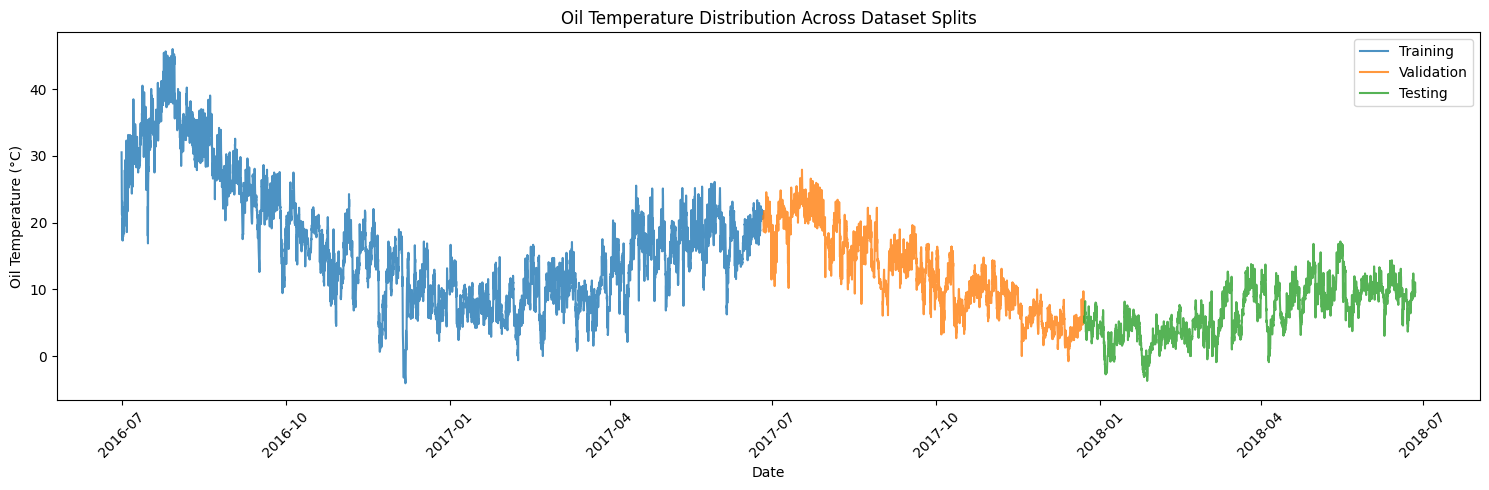

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    date_time.iloc[:num_train_samples],
    train_ot,
    label="Training",
    alpha=0.8
)

plt.plot(
    date_time.iloc[
        num_train_samples:
        num_train_samples + num_val_samples
    ],
    val_ot,
    label="Validation",
    alpha=0.8
)

plt.plot(
    date_time.iloc[
        num_train_samples + num_val_samples:
    ],
    test_ot,
    label="Testing",
    alpha=0.8
)

plt.title("Oil Temperature Distribution Across Dataset Splits")
plt.xlabel("Date")
plt.ylabel("Oil Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

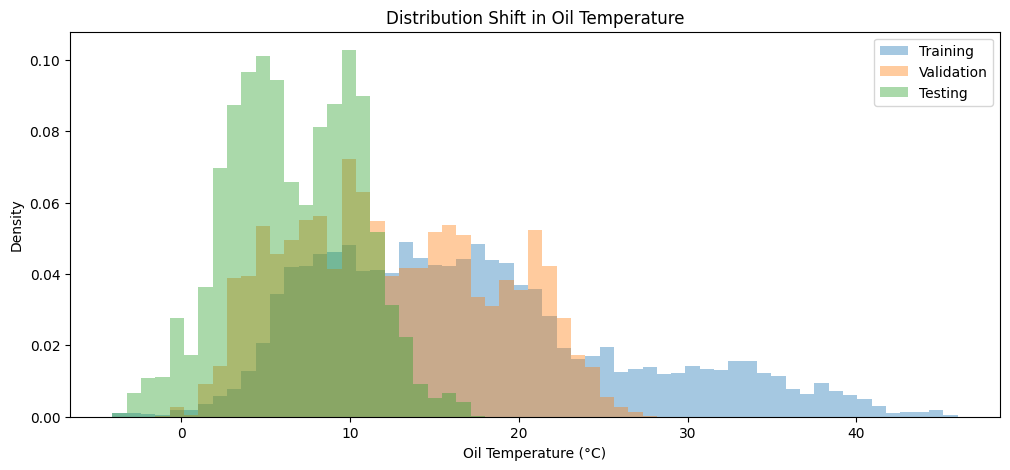

In [ ]:
plt.figure(figsize=(12, 5))

bins = np.linspace(
    df_original['OT'].min(),
    df_original['OT'].max(),
    60
)

plt.hist(
    train_ot, bins=bins, density=True,
    alpha=0.4, label="Training"
)

plt.hist(
    val_ot, bins=bins, density=True,
    alpha=0.4, label="Validation"
)

plt.hist(
    test_ot, bins=bins, density=True,
    alpha=0.4, label="Testing"
)

plt.title("Distribution Shift in Oil Temperature")
plt.xlabel("Oil Temperature (°C)")
plt.ylabel("Density")
plt.legend()
plt.show()

6.6 Implement RevIN in Keras

In [ ]:
@keras.utils.register_keras_serializable()
class RevINNormalization(layers.Layer):

    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def call(self, inputs):

        # Mean of each feature across time steps
        mean = tf.reduce_mean(
            inputs, axis=1, keepdims=True
        )

        # Variance of each feature across time steps
        variance = tf.math.reduce_variance(
            inputs, axis=1, keepdims=True
        )

        # Standard deviation
        std = tf.sqrt(variance + self.epsilon)

        # Treat statistics as fixed during backpropagation
        mean = tf.stop_gradient(mean)
        std = tf.stop_gradient(std)

        # Normalize the input sequence
        normalized = (inputs - mean) / std

        return normalized, mean, std

    def get_config(self):
        config = super().get_config()
        config.update({"epsilon": self.epsilon})
        return config

Denormalization layer

In [ ]:
@keras.utils.register_keras_serializable()
class RevINDenormalization(layers.Layer):

    def __init__(self, temp_index, **kwargs):
        super().__init__(**kwargs)
        self.temp_index = temp_index

    def call(self, inputs):

        predictions, mean, std = inputs

        # Extract only oil temperature statistics
        ot_mean = mean[:, :, self.temp_index]
        ot_std = std[:, :, self.temp_index]

        # Reverse instance normalization
        output = predictions * ot_std + ot_mean

        return output

    def get_config(self):
        config = super().get_config()
        config.update({"temp_index": self.temp_index})
        return config

6.7 Verify that RevIN works correctly

In [ ]:
for samples, targets in train_dataset.take(1):

    revin_norm = RevINNormalization()

    normalized, local_mean, local_std = revin_norm(
        samples
    )

    print("Original shape:", samples.shape)
    print("Normalized shape:", normalized.shape)
    print("Mean shape:", local_mean.shape)
    print("Standard deviation shape:", local_std.shape)

    print("\nMean of OT in first normalized sequence:")
    print(
        tf.reduce_mean(
            normalized[0, :, temp_index]
        ).numpy()
    )

    print("\nStd of OT in first normalized sequence:")
    print(
        tf.math.reduce_std(
            normalized[0, :, temp_index]
        ).numpy()
    )

    # Reverse normalization to reconstruct the inputs
    reconstructed = (
        normalized * local_std + local_mean
    )

    print("\nMaximum reconstruction error:")
    print(
        tf.reduce_max(
            tf.abs(samples - reconstructed)
        ).numpy()
    )

Original shape: (256, 120, 11)
Normalized shape: (256, 120, 11)
Mean shape: (256, 1, 11)
Standard deviation shape: (256, 1, 11)

Mean of OT in first normalized sequence:
2.5431316e-07

Std of OT in first normalized sequence:
0.99997985

Maximum reconstruction error:
2.3841858e-07


6.8 Add RevIN to our best LSTM

In [ ]:
def build_revin_lstm(sequence_length, num_features):

    inputs = keras.Input(
        shape=(sequence_length, num_features)
    )

    # RevIN normalization
    normalized, mean, std = RevINNormalization()(inputs)

    # Original LSTM architecture
    x = layers.LSTM(16)(normalized)

    predictions = layers.Dense(1)(x)

    # RevIN denormalization
    outputs = RevINDenormalization(
        temp_index=temp_index
    )([predictions, mean, std])

    model = keras.Model(inputs, outputs)

    return model

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

revin_model = build_revin_lstm(
    sequence_length=best_sequence_length,
    num_features=num_features
)

revin_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 120, 11)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rev_in_normalizati… │ [(None, 120, 11), │          0 │ input_layer[0][0] │
│ (RevINNormalizatio… │ (None, 1, 11),    │            │                   │
│                     │ (None, 1, 11)]    │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 16)        │      1,792 │ rev_in_normaliza… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │         17 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rev_in_denormaliza… │ (None, 1)         │          0 │ dense[0][0],      │
│ (RevINDenormalizat… │                   │            │ rev_in_normaliza… │
│                     │                   │            │ rev_in_normaliza… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,809 (7.07 KB)

 Trainable params: 1,809 (7.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
revin_train_dataset, revin_val_dataset, revin_test_dataset = (
    create_datasets(
        sequence_length=best_sequence_length,
        horizon=96,
        batch_size=256
    )
)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    "revin_lstm.keras",
    monitor="val_loss",
    save_best_only=True
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=1e-4,
    restore_best_weights=True
)

revin_model.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

revin_history = revin_model.fit(
    revin_train_dataset,
    epochs=50,
    validation_data=revin_val_dataset,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.2280 - mae: 0.3727 - val_loss: 0.1058 - val_mae: 0.2633
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.2181 - mae: 0.3630 - val_loss: 0.1042 - val_mae: 0.2604
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.2134 - mae: 0.3577 - val_loss: 0.1038 - val_mae: 0.2592
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.2105 - mae: 0.3543 - val_loss: 0.1040 - val_mae: 0.2590
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.2086 - mae: 0.3519 - val_loss: 0.1043 - val_mae: 0.2592
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.2071 - mae: 0.3501 - val_loss: 0.1048 - val_mae: 0.2596
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.2058 - mae: 0.3486 - val_loss: 0.1052 - val_mae: 0.2601
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.2046 - mae: 0.3472 - val_loss: 0.1057 - val_mae: 0.2606
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.203

In [ ]:
revin_model = keras.models.load_model(
    "revin_lstm.keras"
)

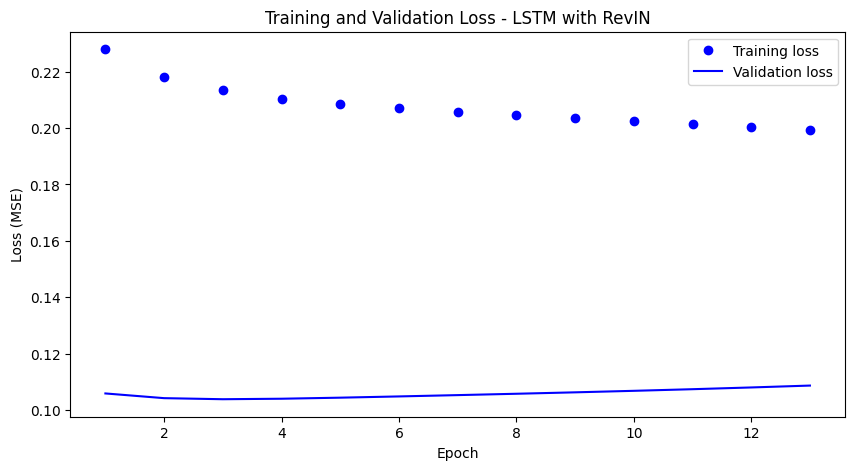

In [ ]:
loss = revin_history.history["loss"]
val_loss = revin_history.history["val_loss"]

epochs = range(1, len(loss) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs, loss, "bo",
    label="Training loss"
)

plt.plot(
    epochs, val_loss, "b",
    label="Validation loss"
)

plt.title("Training and Validation Loss - LSTM with RevIN")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(histories["Experiment_A"]["val_loss"]) + 1),
    histories["Experiment_A"]["val_loss"],
    label="LSTM without RevIN",
    marker="o"
)

plt.plot(
    range(1, len(val_loss) + 1),
    val_loss,
    label="LSTM with RevIN",
    marker="o"
)

plt.title("Impact of RevIN on Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss (MSE)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

NameError: name 'plt' is not defined

 Evaluate the RevIN model

In [ ]:
revin_mae = evaluate_model(
    revin_val_dataset,
    model=revin_model
)

common_revin_val_dataset = (
    revin_val_dataset
    .unbatch()
    .skip(336 - best_sequence_length)
    .batch(256)
)

common_revin_mae = evaluate_model(
    common_revin_val_dataset,
    model=revin_model
)

print(f"Validation MAE: {revin_mae:.4f} °C")

print(
    f"Common Validation MAE: "
    f"{common_revin_mae:.4f} °C"
)

print("Total epochs:", len(loss))

print(
    "Best epoch:",
    np.argmin(val_loss) + 1
)

print("Best validation loss:", min(val_loss))

In [ ]:
final_comparison_df = pd.DataFrame({
    "Model": [
        "Common-sense Baseline",
        "LSTM without RevIN",
        "Best CNN",
        "LSTM with RevIN"
    ],
    "Validation MAE": [
        float(baseline_mae),
        float(best_lstm_mae),
        float(best_cnn_mae),
        float(revin_mae)
    ]
})

display(
    final_comparison_df
    .sort_values("Validation MAE")
    .round(4)
)

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Validation MAE"]
)

plt.axhline(
    y=baseline_mae,
    color="red",
    linestyle="--",
    label=f"Baseline: {baseline_mae:.2f} °C"
)

plt.title("Impact of Reversible Instance Normalization")
plt.ylabel("Validation MAE (°C)")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()


### Comparison with the Original LSTM

I integrated RevIN into Experiment A, which was the best recurrent model from Task 4.

I kept the sequence length, LSTM units, optimizer, learning rate, batch size, early stopping patience and random seed unchanged to isolate the effect of RevIN.

Both models contain 1,809 trainable parameters because my RevIN implementation does not introduce any learnable parameters.

| Model | Validation MAE (°C) |
|---|---:|
| LSTM without RevIN | 3.7711 |
| LSTM with RevIN | 2.3786 |

Adding RevIN reduced the validation MAE from 3.7711°C to 2.3786°C, representing an improvement of approximately 36.93%.

When evaluated on common validation timestamps, the MAE also decreased from 3.8229°C to 2.3874°C.

### Analysis of Training and Validation Loss

Both LSTM models trained for 13 epochs and achieved their best validation loss at epoch 3.

The original LSTM achieved a minimum validation loss of 0.24708, whereas the LSTM with RevIN achieved a minimum validation loss of 0.10378, representing a reduction of approximately 58%.

The validation loss of the original LSTM increased considerably after epoch 3. In contrast, the validation loss of the RevIN model remained relatively stable.

Although the RevIN training loss continued to decrease while its validation loss increased slightly after epoch 3, the deterioration was much smaller than in the original model.

This suggests that RevIN improved the model's generalization to the validation data.

### Comparison with All Previous Models

| Model | Validation MAE (°C) |
|---|---:|
| LSTM with RevIN | 2.3786 |
| Common-sense Baseline | 2.6554 |
| Best CNN | 3.7597 |
| LSTM without RevIN | 3.7711 |

The LSTM with RevIN achieved the lowest validation MAE among all the models tested.

It also outperformed the common-sense baseline by approximately 10.42%, making it the first deep learning model in this assignment to outperform the baseline.

### Conclusion

The results support my initial hypothesis that distribution shift was a contributing factor to the poor forecasting performance of the original LSTM.

By normalizing each input sequence independently and restoring its local statistics after forecasting, RevIN improved the model's ability to generalize to data with different temperature distributions.

The improvement was achieved without increasing the number of trainable parameters or changing the original LSTM architecture.

Based on the validation MAE, I selected the LSTM with RevIN as my best forecasting model for the final test set evaluation in Task 7.

## Task 7: Test Set Evaluation

### Final Model Selection

Based on the validation MAE from the previous experiments, I selected the LSTM with RevIN as my final forecasting model because it achieved the lowest validation MAE of 2.3786°C.

I loaded the best saved checkpoint from Task 6 and evaluated it on the unseen test dataset without additional training or hyperparameter tuning.

### Test Set Performance

The test dataset contains 4,460 hourly observations, resulting in 4,245 valid input-target sequences.

| Model | Validation MAE (°C) | Test MAE (°C) |
|---|---:|---:|
| Common-sense Baseline | 2.6554 | 2.8526 |
| LSTM with RevIN | 2.3786 | 2.5511 |

The LSTM with RevIN achieved a test MAE of 2.5511°C, compared to the baseline MAE of 2.8526°C. This represents an improvement of approximately 10.57% over the baseline.

Although the MAE increased from 2.3786°C on the validation set to 2.5511°C on the test set, the model continued to outperform the baseline. This suggests that the benefits of RevIN generalize to unseen data.

In [ ]:
final_model = keras.models.load_model(
    "revin_lstm.keras"
)

final_model.summary()

In [ ]:
final_test_dataset = revin_test_dataset

print("Number of test observations:", num_test_samples)

print("Number of test sequences:",
      count_sequences(final_test_dataset))

for samples, targets in final_test_dataset.take(1):

    print("Input shape:", samples.shape)
    print("Target shape:", targets.shape)

7.3 Evaluate the final model and baseline

In [ ]:
test_predictions = []
test_actual = []
test_baseline_predictions = []

for samples, targets in final_test_dataset:

    # LSTM with RevIN predictions
    preds = final_model.predict(
        samples, verbose=0
    ).flatten()

    # Common-sense baseline predictions
    baseline_preds = samples[:, -1, temp_index].numpy()

    targets = targets.numpy()

    # Convert model predictions and targets to Celsius
    preds, actual = unnormalize(
        preds,
        targets,
        train_mean['OT'],
        train_std['OT']
    )

    # Convert baseline predictions to Celsius
    baseline_preds = (
        baseline_preds * train_std['OT']
        + train_mean['OT']
    )

    # Store results
    test_predictions.extend(preds)
    test_actual.extend(actual)
    test_baseline_predictions.extend(baseline_preds)

# Convert lists into NumPy arrays
test_predictions = np.array(test_predictions)
test_actual = np.array(test_actual)

test_baseline_predictions = np.array(
    test_baseline_predictions
)

7.4 Calculate test MAE

In [ ]:
# Absolute prediction errors
model_errors = np.abs(
    test_actual - test_predictions
)

baseline_errors = np.abs(
    test_actual - test_baseline_predictions
)

# Mean Absolute Error
test_model_mae = np.mean(model_errors)

test_baseline_mae = np.mean(baseline_errors)

print("Number of predictions:", len(test_predictions))

print(f"Test MAE - LSTM with RevIN: "
      f"{test_model_mae:.4f} °C")

print(f"Test MAE - Baseline: "
      f"{test_baseline_mae:.4f} °C")

Calculate improvement over the baseline

In [ ]:
test_improvement = (
    (test_baseline_mae - test_model_mae)
    / test_baseline_mae
) * 100

print(f"Improvement over baseline: "
      f"{test_improvement:.2f}%")

7.5 Compare validation and test performance

In [ ]:
test_results_df = pd.DataFrame({
    "Model": [
        "Common-sense Baseline",
        "LSTM with RevIN"
    ],
    "Validation MAE": [
        float(baseline_mae),
        float(revin_mae)
    ],
    "Test MAE": [
        float(test_baseline_mae),
        float(test_model_mae)
    ]
})

display(test_results_df.round(4))

In [ ]:
test_results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Validation and Test MAE Comparison")
plt.ylabel("MAE (°C)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
test_start_index = (
    num_train_samples + num_val_samples
)

final_delay = best_sequence_length + horizon - 1

test_dates = date_time.iloc[
    test_start_index + final_delay:
].reset_index(drop=True)

print("First prediction date:", test_dates.iloc[0])
print("Last prediction date:", test_dates.iloc[-1])

print("Number of timestamps:", len(test_dates))
print("Number of predictions:", len(test_predictions))

assert len(test_dates) == len(test_predictions)

7.7 Plot two weeks of predicted and actual temperature

In [ ]:
hours = 14 * 24

plt.figure(figsize=(16, 6))

plt.plot(
    test_dates.iloc[:hours],
    test_actual[:hours],
    label="Actual Oil Temperature",
    linewidth=2
)

plt.plot(
    test_dates.iloc[:hours],
    test_predictions[:hours],
    label="LSTM with RevIN",
    linestyle="--"
)

plt.plot(
    test_dates.iloc[:hours],
    test_baseline_predictions[:hours],
    label="Common-sense Baseline",
    linestyle=":",
    alpha=0.8
)

plt.title("Oil Temperature Forecasting - Two Weeks of Test Data")
plt.xlabel("Date")
plt.ylabel("Oil Temperature (°C)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Analysis of Two Weeks of Predictions

I plotted the first 336 available hourly predictions from the test dataset, representing two weeks of oil temperature forecasts.

#### Where the Model Performs Well

- Between January 1 and January 2, the model follows the general temperature pattern and captures the gradual increase in oil temperature.
- Around January 9 and January 10, the model captures some of the temperature fluctuations, with several predictions close to the actual values.
- Around January 13, the predicted and actual temperatures are relatively close during periods of stable temperature.
- The model generally produces smoother predictions than the common-sense baseline and avoids some of its extreme fluctuations.

These observations suggest that the model performs reasonably well when temperature changes are gradual or relatively stable.

#### Where the Model Performs Poorly

- Between January 3 and January 5, the actual temperature drops to approximately −2.7°C, while the model continues predicting temperatures between approximately 4°C and 5°C. This results in substantial overestimation.
- Between January 7 and January 8, the actual temperature remains close to 0°C for several hours, while the model predicts higher temperatures.
- Around January 11 and January 12, the model underestimates several temperature peaks.
- Around January 14, the actual temperature increases sharply to approximately 8°C, while the predicted temperature remains close to 2°C.

These observations indicate that the model struggles to predict sudden temperature changes and extreme values. Its predictions are smoother than the actual temperature measurements, resulting in overestimation during sharp decreases and underestimation during sharp increases.

One possible reason is the forecast horizon of 96 hours, which makes unexpected future temperature changes difficult to predict using historical observations alone.

### Conclusion

The LSTM with RevIN outperformed the common-sense baseline on both the validation and test datasets.

Although the model struggles with sudden temperature changes and extreme values, it generally captures gradual temperature patterns and achieves a lower overall forecasting error.

The results demonstrate that reversible instance normalization improved forecasting performance under the observed distribution shift without introducing additional trainable parameters.